# Lab 17: How to run model-written code safely

**Notebook 2 of 2: the code interpreter at the Chinook desk**

## Goal

Build a chart agent for the Chinook music shop: the model reads the shop's database through a `run_sql` tool that
runs in our notebook, and draws charts with OpenAI's hosted code interpreter, so the code it writes never runs on
our machine. Asked for the shop's revenue by year, the agent draws the right chart, and the code behind it shows
how the numbers got there: the model read them in the query result and typed them into the code. Nothing checks a
number on that path. We then change one tool so that the rows travel from the database to the code as a file, and
the model never types them. For readers with Docker, an optional last part runs code a model wrote in a container
on your own machine, and takes a look inside it.

## What you will learn

- How to give one agent two kinds of tool on the Responses API: a function that runs in our Python (`run_sql`) and
  a hosted tool that runs on OpenAI's side (the code interpreter), and how to read a run item by item.
- How to check where a chart's numbers came from by reading the code that drew it, and count the totals the model
  typed in.
- How to hand a query's rows to the code interpreter as a file, with `client.files.create` and the container's
  `file_ids`, so the model never types the numbers into its code and sees only what the code prints.
- (Optional, with Docker) How to run code a model wrote in a container on your own machine with no network, a
  read-only root, limits, a user who is not root and one mounted folder, and what the code can reach inside it.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it (lab 00 explains it line by line).

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The second cell makes the OpenAI client (each request may take up to 120 seconds, since running code takes longer
than a plain answer), the folder this notebook writes to (`outputs/`, which git ignores), and the connection to the
shop's database. The connection is **read-only** (`mode=ro`): whatever SQL runs on it, the database cannot change.
`omit`, imported with the client, is how a request leaves an argument out: `reasoning={"effort": EFFORT or omit}`
sends no effort at all when `models.env` leaves it empty.

In [2]:
import json
import sqlite3
from openai import OpenAI, omit

client = OpenAI(timeout=120)

OUTPUTS = ROOT / "17_Code_Execution" / "outputs"
OUTPUTS.mkdir(exist_ok=True)

DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)
print("files go to:", OUTPUTS.relative_to(ROOT))
print("invoices in the database:", conn.execute("SELECT COUNT(*) FROM invoices").fetchone()[0])

files go to: 17_Code_Execution/outputs
invoices in the database: 412


The shop's database has 412 invoices, one per sale. The connection is opened with `check_same_thread=False`; this
notebook uses it from one thread only, because `run_sql` runs in our single loop.

---

## Part A: Work out the answer the chart must show

The question the agent will get is *the shop's revenue by year*. Before any agent draws it, we work out the answer
with our own query, so we can check the agent's chart against it later. Each row of the `invoices` table is one
sale, with its date in `InvoiceDate` and its amount in `Total`:

- `strftime('%Y', InvoiceDate)` keeps only the year of each date, as text (`'2009'`);
- `SUM(Total)` adds the totals of each year, and `ROUND(..., 2)` rounds the sum to cents;
- `GROUP BY year` makes one row per year.

In [3]:
YEARLY_SQL = """
SELECT strftime('%Y', InvoiceDate) AS year, ROUND(SUM(Total), 2) AS revenue
FROM invoices
GROUP BY year
ORDER BY year
"""
TRUTH = dict(conn.execute(YEARLY_SQL).fetchall())
print(TRUTH)

{'2009': 449.46, '2010': 481.45, '2011': 469.58, '2012': 477.53, '2013': 450.58}


Five years, 2009 to 2013. `fetchall()` returns a list of `(year, revenue)` pairs, and `dict(...)` turns each pair into
one entry, so `TRUTH["2010"]` is that year's revenue. The years are close: the highest, 2010, is $481.45 and the
lowest, 2009, is $449.46. On a bar chart, one mistyped digit in one bar would hardly show.

**Checkpoint A.** Five totals: 2009 $449.46, 2010 $481.45, 2011 $469.58, 2012 $477.53, 2013 $450.58.

---

## Part B: Build a chart agent from run_sql and the code interpreter

The agent gets two tools, and they run in different places:

| Tool | Who writes what it runs | Where it runs |
|---|---|---|
| `run_sql` | the model writes a SQL query; our Python function runs it | in this notebook, on the read-only connection |
| the code interpreter | the model writes Python | in a container on OpenAI's side |

So code from the model never runs here. A query from the model does, and the read-only connection keeps that query
from changing anything. It does not limit what a query reads or how long it runs; a real desk would give the agent
a database user that sees only the tables it needs.

### The run_sql tool, called by hand

`run_sql` runs one query and returns its rows as JSON text (`json.dumps`), because a tool's result reaches the model
as text. It returns at most 50 rows (`fetchmany(50)`), so a query that matches thousands of rows cannot flood the
model. A query that fails returns the error as text, so the model can read it and try again. Two calls by hand: our
yearly query, and a delete.

In [4]:
def run_sql(query):
    """Run one query on the read-only database; return at most 50 rows as JSON text, or the error."""
    try:
        return json.dumps(conn.execute(query).fetchmany(50))
    except sqlite3.Error as error:
        return f"SQLite error: {error}"


print(run_sql(YEARLY_SQL))
print(run_sql("DELETE FROM invoices WHERE InvoiceId = 1"))

[["2009", 449.46], ["2010", 481.45], ["2011", 469.58], ["2012", 477.53], ["2013", 450.58]]
SQLite error: attempt to write a readonly database


The five rows as JSON, and `SQLite error: attempt to write a readonly database` for the delete. Whatever query the
model writes, the shop's data stays as it is.

### The tools and the instructions

Each tool is one dictionary in `TOOLS`:

- `run_sql` is a **function tool**: our schema says its name, what it does and its one argument, `query`. The
  description names the table and the two columns the question needs, so the model does not have to guess them.
  `"strict": True` with `"additionalProperties": False` makes the model's arguments match the schema exactly: one
  `query` string, nothing else.
- `CODE_INTERPRETER` is the hosted tool: `"type": "auto"` starts a container for the request, `"memory_limit": "1g"`
  is the smallest size, and `"network_policy": {"type": "disabled"}` gives it no internet (the default, written
  out).

The instructions say which tool does what, and ask for every chart to be shown with `plt.show()`: a chart that is
shown comes back in the response as an image, while a chart that is only saved stays in the container.

In [5]:
CODE_INTERPRETER = {
    "type": "code_interpreter",
    "container": {"type": "auto", "memory_limit": "1g", "network_policy": {"type": "disabled"}},
}
RUN_SQL = {
    "type": "function",
    "name": "run_sql",
    "description": ("Run one read-only SQLite query on the Chinook music shop's database. The table invoices has "
                    "one row per sale, with InvoiceDate (text, 'YYYY-MM-DD HH:MM:SS') and Total (US dollars)."),
    "parameters": {
        "type": "object",
        "properties": {"query": {"type": "string"}},
        "required": ["query"],
        "additionalProperties": False,
    },
    "strict": True,
}
TOOLS = [RUN_SQL, CODE_INTERPRETER]

SYSTEM = ("You are the Chinook music shop's data assistant. Use run_sql to read the database and the python tool "
          "to draw charts. Show every chart with plt.show().")
QUESTION = "Make a bar chart of the shop's revenue by year."
print([tool.get("name", tool["type"]) for tool in TOOLS])

['run_sql', 'code_interpreter']


### The loop

The two tools need different work from us. A code interpreter call happens inside one request: the API runs the
code and the model carries on, so a single response can contain several. A `run_sql` call is only a request: the
response ends with a `function_call` item, and nothing happens until our code runs the query and sends the result
back. So `ask_chart_agent` loops over the `run_sql` calls only. Step by step:

1. Send the question with the instructions and the tools.
2. Collect the `function_call` items of the latest response. If there are none, the model has answered: stop.
3. Otherwise run each query with `run_sql`, and build one `function_call_output` per call, with the same `call_id`.
4. Send the outputs back with `previous_response_id`, so the API continues from the response before, and go back
   to step 2. The instructions and tools are not carried over, so we send them again.

A `function_call` item has a `call_id` and `arguments`, the model's arguments as a JSON string: `json.loads` turns
the string into a dictionary, so `json.loads(call.arguments)["query"]` is the SQL. Every request passes
`include=["code_interpreter_call.outputs"]`, which asks the API to send back what the model's code printed and
drew; without it, a code interpreter item has the code but not its output.

`max_turns=6` caps the loop, so a model that keeps asking for queries cannot run forever. The function returns
every response of the run, in order, so we can read the run afterwards.

In [6]:
def ask_chart_agent(question, max_turns=6):
    """Send the question; run every run_sql call the model asks for; stop when a response asks for none."""
    response = client.responses.create(
        model=MODEL, reasoning={"effort": EFFORT or omit}, instructions=SYSTEM,
        input=question, tools=TOOLS, include=["code_interpreter_call.outputs"],
    )
    responses = [response]
    for turn in range(max_turns):
        calls = [item for item in response.output if item.type == "function_call"]
        if not calls:
            break
        outputs = [{"type": "function_call_output", "call_id": call.call_id,
                    "output": run_sql(json.loads(call.arguments)["query"])} for call in calls]
        response = client.responses.create(
            model=MODEL, reasoning={"effort": EFFORT or omit}, instructions=SYSTEM,
            previous_response_id=response.id, input=outputs, tools=TOOLS,
            include=["code_interpreter_call.outputs"],
        )
        responses.append(response)
    return responses

Two small helpers read a run. A response's `output` is a list of items of three kinds: `function_call` (a
`run_sql` request), `code_interpreter_call` (code that ran in the container: `item.code` is the code, and
`item.outputs` is what it produced, where a `logs` entry is printed text and an `image` entry is a chart) and
`message` (the reply). `show_run` prints every item of every response, numbered by the model call it came
from. `show_chart` finds the last image the code interpreter sent back, decodes it (the image is a data URL: the text
`data:image/png;base64,` and then the PNG file as base64 text), saves it in `outputs/` and shows it.

In [7]:
import base64
from IPython.display import Image, display


def show_run(responses):
    """Print each item of each response: our run_sql calls, the code interpreter's runs, the reply."""
    for number, response in enumerate(responses, 1):
        for item in response.output:
            if item.type == "function_call":
                print(f"call {number}  run_sql (our code):", json.loads(item.arguments)["query"].strip())
            elif item.type == "code_interpreter_call":
                kinds = [output.type for output in item.outputs or []]
                print(f"call {number}  code interpreter (OpenAI's container): {len(item.code.splitlines())} lines, outputs {kinds}")
            elif item.type == "message":
                print(f"call {number}  reply:", response.output_text)


def show_chart(responses, filename):
    """Save and show the last chart the code interpreter returned."""
    images = [output for r in responses for item in r.output if item.type == "code_interpreter_call"
              for output in item.outputs or [] if output.type == "image"]
    if not images:
        print("No chart came back: the code saved it in the container without showing it.")
        return
    png = base64.b64decode(images[-1].url.split(",", 1)[1])
    (OUTPUTS / filename).write_bytes(png)
    display(Image(data=png, width=600))

Now the agent, on the question. ⚠️ **This cell costs money:** one container session
(`PRICE_CONTAINER_SESSION_USD` in `models.env`, up to $0.03 for 1 GB) plus the tokens.

call 1  run_sql (our code): SELECT substr(InvoiceDate, 1, 4) AS year, ROUND(SUM(Total), 2) AS revenue FROM invoices GROUP BY substr(InvoiceDate, 1, 4) ORDER BY year;
call 2  code interpreter (OpenAI's container): 13 lines, outputs ['image']
call 2  reply: Revenue peaked in 2010 at **$481.45** and was lowest in 2009 at **$449.46**.


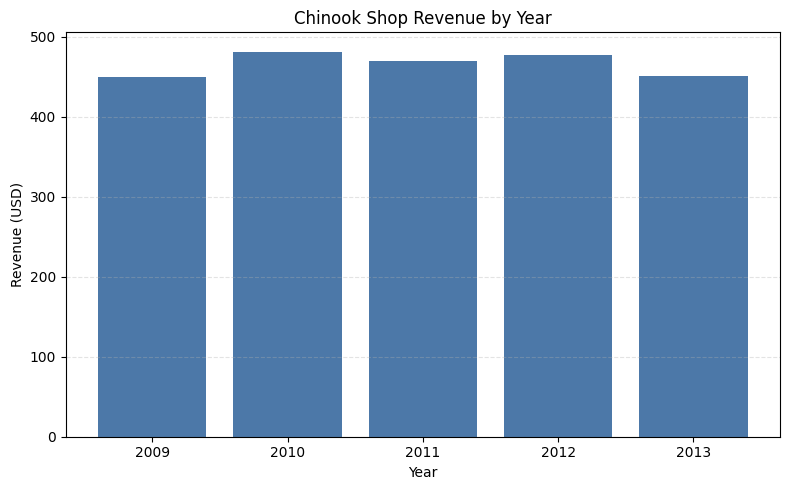

In [8]:
run_typed = ask_chart_agent(QUESTION)
show_run(run_typed)
show_chart(run_typed, "chart_typed.png")

In our run the agent made two model calls. In call 1 the model asked for one query, a yearly total written its own way (`substr(InvoiceDate, 1, 4)` keeps the first four characters of the date, the year), and our code ran it. In call 2 the model ran 13 lines of code in the container, which drew the chart, and then replied. The reply names 2010 as the highest year at $481.45 and 2009 as the lowest at $449.46, as in Part A.

**Checkpoint B.** A `run_sql` call with a yearly query (our code ran it), then a code interpreter run with an `image`
output (OpenAI's container ran it), a short reply, and a bar chart of five years saved as `outputs/chart_typed.png`.

---

## Part C: Check where the chart's numbers came from

The chart looks like the answer of Part A. But the container that drew it has no database and no network: the code
could not have read the shop's data. So where did the bar heights come from? The code says. `code_calls` collects
the code interpreter items of a run, and we print the code of the last one, the one that drew the chart.

In [9]:
def code_calls(responses):
    """Every code_interpreter_call item of a run, in order."""
    return [item for r in responses for item in r.output if item.type == "code_interpreter_call"]


chart_code = code_calls(run_typed)[-1].code
print(chart_code)

import matplotlib.pyplot as plt

years = ["2009", "2010", "2011", "2012", "2013"]
revenue = [449.46, 481.45, 469.58, 477.53, 450.58]

plt.figure(figsize=(8, 5))
plt.bar(years, revenue, color="#4C78A8")
plt.title("Chinook Shop Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue (USD)")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()



The answer is in lines 3 and 4. `years` and `revenue` are two lists the model typed, and `revenue = [449.46, 481.45, 469.58, 477.53, 450.58]` are the five totals it read in `run_sql`'s result. They look like Part A's.

We check that in code rather than by eye. `re.findall(r"\d+\.\d+", code)` finds every decimal number in the text
(`\d+` is one or more digits, `\.` a dot). Each becomes a `float` rounded to cents, and for each year we look for the
true revenue among them. `totals_typed_in` does the same for all five years and returns the count.

In [10]:
import re


def totals_typed_in(code):
    """How many of the five true yearly totals appear as numbers typed into the code."""
    typed = {round(float(number), 2) for number in re.findall(r"\d+\.\d+", code)}
    return sum(revenue in typed for revenue in TRUTH.values())


typed = {round(float(number), 2) for number in re.findall(r"\d+\.\d+", chart_code)}
for year, revenue in TRUTH.items():
    print(year, revenue, "| typed into the code:", revenue in typed)
print("totals typed in:", totals_typed_in(chart_code), "of 5")

2009 449.46 | typed into the code: True
2010 481.45 | typed into the code: True
2011 469.58 | typed into the code: True
2012 477.53 | typed into the code: True
2013 450.58 | typed into the code: True
totals typed in: 5 of 5


All five are there, each equal to the database's value: `5 of 5`. In every run we made before the change in Part D,
the model typed all five totals in.

**What this check shows, and what it leaves open.** In this run every bar height in the code equals the database's
value, so the chart is right. The path the numbers took is the problem: the database, then `run_sql`'s result as
text, then the model reading that text, then the model typing numbers into code. A model that copies five numbers
correctly can swap two digits in the sixth, or in a table of five hundred rows. A wrong number would draw a wrong
bar with no error anywhere, and nothing in the container could catch it, since the database is never there.

**Checkpoint C.** The chart's code contains the five yearly totals as numbers, each equal to the database's value:
`totals typed in: 5 of 5`.

---

## Part D: Hand the rows to the code instead of the model

The fix is to let the rows reach the code as a file, so the model never types them. The code interpreter can work on
files: the tool's container settings take `file_ids`, a list of files uploaded to OpenAI, and the API puts those
files in the container, in the folder `/mnt/data`. So `run_sql` changes in two ways:

1. It saves the query's rows as a CSV file and uploads it, and puts the file's id in the container settings.
2. It returns to the model only the **shape** of the result: how many rows, which columns, and where the file is.
   `run_sql` no longer sends the numbers, so the model has none to type into its code. It can still see them if
   its own code prints the table, since what the code prints goes back to the model; but the code reads the
   numbers from the file.

The picture shows the two paths. The dashed arrow is what the code prints, which goes back to the model:

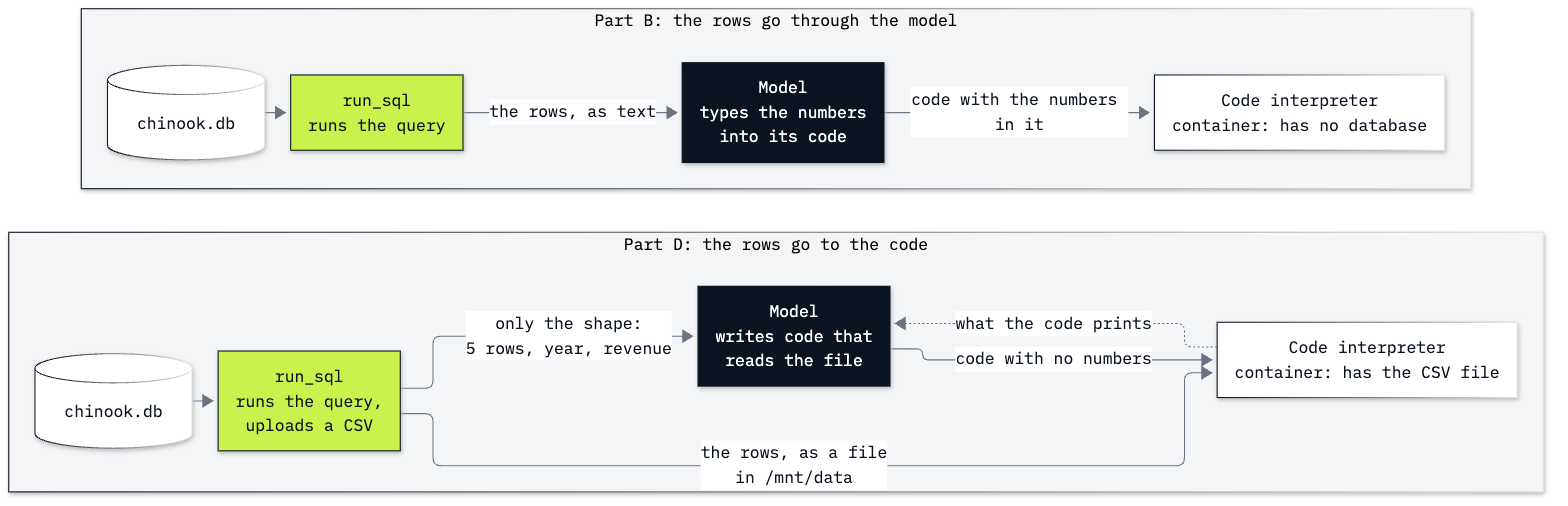

In [11]:
display(Image(filename=ROOT / "17_Code_Execution" / "resources" / "lab17_data_paths.png", width=760))

The new `run_sql`, step by step:

1. Run the query. `cursor.description` lists the result's columns; `column[0]` is each one's name.
2. Write a CSV in memory: `io.StringIO()` is a text buffer that acts like a file, and `csv.writer` writes the header
   row (`writerow`) and then every data row (`writerows`). All the rows go in the file, not just 50: the model does
   not read them, so their number no longer matters.
3. Upload it with `client.files.create`: `file=(name, bytes)` gives the file a name and its content
   (`.encode()` turns the text into bytes), and `purpose="user_data"` marks it as a file for the model's tools.
4. Put the file's id in `CODE_INTERPRETER["container"]["file_ids"]`. `TOOLS` contains that same dictionary, not a
   copy, so the next request the loop sends carries the file, and the container that request starts has it.
5. Return the shape of the result as one sentence.

`UPLOADED` keeps every file id, so we can delete the files at the end of this part. The loop does not change: it
calls `run_sql` by name, so it uses whichever `run_sql` is defined when it runs.

In [12]:
import csv
import io

UPLOADED = []    # every file we upload, to delete at the end of this part


def run_sql(query):
    """Run the query; upload all its rows as a CSV file for the code interpreter; tell the model only their shape."""
    try:
        cursor = conn.execute(query)
    except sqlite3.Error as error:
        return f"SQLite error: {error}"
    columns = [column[0] for column in cursor.description]
    rows = cursor.fetchall()

    text = io.StringIO()
    writer = csv.writer(text)
    writer.writerow(columns)
    writer.writerows(rows)
    uploaded = client.files.create(file=("query_result.csv", text.getvalue().encode()), purpose="user_data")
    UPLOADED.append(uploaded.id)
    CODE_INTERPRETER["container"]["file_ids"] = [uploaded.id]

    return (f"{len(rows)} rows, columns {', '.join(columns)}, saved for the python tool in /mnt/data "
            "as a CSV file whose name ends in query_result.csv.")

One call by hand, with our yearly query. Uploading a file costs nothing by itself; the container session starts
only when the model runs code.

In [13]:
print(run_sql(YEARLY_SQL))
print("file_ids in the container settings:", CODE_INTERPRETER["container"]["file_ids"])

5 rows, columns year, revenue, saved for the python tool in /mnt/data as a CSV file whose name ends in query_result.csv.
file_ids in the container settings: ['file-GTWoShwc9C4SC2isJcwPMk']


This sentence is all the model receives from `run_sql` now: five rows, two columns, and where the file is. The
`file-...` id is the uploaded file. The same question again, with the new `run_sql` in place. ⚠️ **This cell costs money:** one more
container session.

call 1  run_sql (our code): SELECT strftime('%Y', InvoiceDate) AS year, SUM(Total) AS revenue FROM invoices GROUP BY strftime('%Y', InvoiceDate) ORDER BY year;
call 2  code interpreter (OpenAI's container): 4 lines, outputs ['logs']
call 2  code interpreter (OpenAI's container): 8 lines, outputs ['image']
call 2  reply: Here’s the shop’s revenue by year. Revenue peaked in 2010 at **$481.45**.


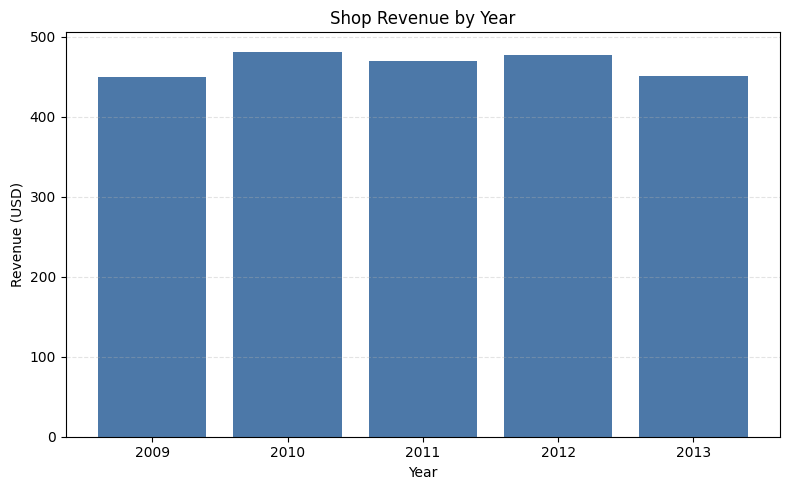

In [14]:
run_file = ask_chart_agent(QUESTION)
show_run(run_file)
show_chart(run_file, "chart_from_file.png")

In our run the agent made the same two model calls. In call 1 our code ran the query and uploaded its rows. In call 2 the model ran two pieces of code: one that loaded the file and printed it (`logs`), and one that drew the chart (`image`). The reply names 2010's $481.45 again: the model read it in the table its first piece of code printed, so it still sees the numbers. The check below shows that it did not type them into its code. Here is all the code the model wrote in this run, and the same check as in Part C, on all of it:

In [15]:
all_code = "\n".join(call.code for call in code_calls(run_file))
print(all_code)
print("totals typed in:", totals_typed_in(all_code), "of 5")

import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('/mnt/data/file-HQNfizoYybTFsMJxJf1sfF-query_result.csv')
df

plt.figure(figsize=(8,5))
plt.bar(df['year'].astype(str), df['revenue'], color='#4C78A8')
plt.title("Shop Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue (USD)")
plt.grid(axis='y', linestyle='--', alpha=0.35)
plt.tight_layout()
plt.show()

totals typed in: 0 of 5


The code reads the file with `pd.read_csv` (pandas, a library for tables, is installed in the container) and draws `df['revenue']`, the column from the file. The path in `read_csv` is the file's id followed by its name, which is how the container stores an uploaded file. No total is typed in: `0 of 5`. The numbers the chart draws now go from the database to the chart through our code
and the file; the model sees only what its code prints, and the chart has the same five bars as before.

The uploaded files stay in the account's file storage until we delete them. `client.files.delete` deletes one by
its id; we delete every file `UPLOADED` recorded (one from the call by hand, one from the agent's run), and take the
file id out of the container settings with `del`.

In [16]:
for file_id in UPLOADED:
    client.files.delete(file_id)
print("deleted", len(UPLOADED), "uploaded files")
UPLOADED.clear()
del CODE_INTERPRETER["container"]["file_ids"]

deleted 2 uploaded files


**Lesson to Remember.** A sandbox (a place where code runs cut off from your files and the network, like the
hosted container) limits what code can *reach*. It does not check what the code *says*. When the
model reads data and writes code, every number in the code went through the model. Hand the data to the code (a
file in the container), and keep the model's part to writing the steps.

**Checkpoint D.** `run_sql` returns one sentence about 5 rows and the columns `year, revenue`; the agent's code reads
the CSV file and prints or draws from it; `totals typed in: 0 of 5`; a chart with the same five bars, saved as
`outputs/chart_from_file.png`; the uploaded files deleted.

---

## Part E (optional): Run model-written code in a container on your own machine

The code interpreter needs only the API key, and that is why it is the main runner in this lab. Some teams cannot
send their data to a hosted container, or want the code to run where the data is. Then the isolated place is a
**container** on your own machine: a process with its own filesystem, built from an **image** (a packaged copy of
an operating system's files plus what we install), with its own network settings and limits. It can reach a folder
of ours only when we **mount** it.

This part needs Docker. Every cell checks first, and without Docker it prints one line and skips; the saved outputs
show our run.

In [17]:
import shutil
import subprocess

SKIP = "Docker is not available: skipped. The saved output shows our run."
DOCKER_OK = False
if shutil.which("docker") is None:
    print("Docker is not installed.", SKIP)
else:
    info = subprocess.run(["docker", "info", "--format", "{{.ServerVersion}}"], capture_output=True, text=True)
    DOCKER_OK = info.returncode == 0
    print("docker server:", info.stdout.strip() if DOCKER_OK else info.stderr.strip()[:200])

docker server: 29.9.2


Our Docker server is version 29.9.2. If yours prints an error or the skip line, the rest of this part skips too.

### Build the image

The image is described by `resources/Dockerfile`: Python 3.13 with matplotlib, and an ordinary user called
`sandbox` that code runs as (Going further reads it line by line). `docker build` turns it into an image named
`chinook-sandbox`. The first build downloads the Python image and installs matplotlib, which needs the internet
once; later builds reuse Docker's cache and finish at once. Then we start one throwaway container from the image to
see what is inside.

In [18]:
LAB = ROOT / "17_Code_Execution"
if DOCKER_OK:
    build = subprocess.run(["docker", "build", "--quiet", "--tag", "chinook-sandbox", str(LAB / "resources")],
                           capture_output=True, text=True)
    print("built:", build.returncode == 0)
    inside = ("import sys, getpass, matplotlib; "
              "print('python', sys.version.split()[0], '| matplotlib', matplotlib.__version__, '| user', getpass.getuser())")
    check = subprocess.run(["docker", "run", "--rm", "chinook-sandbox", "python", "-c", inside],
                           capture_output=True, text=True)
    print(check.stdout.strip())
else:
    print(SKIP)

built: True


python 3.13.18 | matplotlib 3.11.2 | user sandbox


`built: True`, and inside the image Python 3.13.18 runs with matplotlib 3.11.2 as the user `sandbox`: what the Dockerfile asks for.

### The probe in the container

A **probe** is a few lines we wrote that ask what any code could ask, and print only the answers (whether `.env`
exists, never what is in it). It is fixed text, written here. Its five lines ask where the code starts, where
`../..` leads, whether `.env` is there, whether the API key is in the environment, and whether `pypi.org` can be
reached.

The container gets two settings, and they are the two that matter for the probe:

- `--network none`: the container has no network;
- `--volume OUTPUTS:/work`: our `outputs/` folder appears inside the container as `/work`, the folder code starts
  in. Nothing else of ours is mounted.

`--rm` deletes the container when the code ends. `OUTPUTS.chmod(0o777)` lets any user write in `outputs/`: the
container's user `sandbox` is not you, and on Linux it needs that permission to save a chart there.

In [19]:
PROBE = """import os, pathlib, socket
print("working folder:", pathlib.Path.cwd().name)
print("two folders up:", pathlib.Path("../..").resolve().name or "/")
print(".env there:", pathlib.Path("../../.env").exists())
print("key in environment:", "OPENAI_API_KEY" in os.environ)
try:
    socket.create_connection(("pypi.org", 443), timeout=3).close()
    print("network: reachable")
except OSError as error:
    print("network: blocked,", type(error).__name__)
"""
(OUTPUTS / "probe.py").write_text(PROBE)
OUTPUTS.chmod(0o777)
MOUNT = ["--volume", f"{OUTPUTS}:/work"]

if DOCKER_OK:
    result = subprocess.run(["docker", "run", "--rm", "--network", "none", *MOUNT, "chinook-sandbox", "python", "probe.py"],
                            capture_output=True, text=True)
    print(result.stdout + result.stderr)
else:
    print(SKIP)

working folder: work
two folders up: /
.env there: False
key in environment: False
network: blocked, gaierror



The container's answers to the five lines:

- **working folder: work**: the probe started in `/work`, which is our `outputs/` folder.
- **two folders up: /**: from `/work`, `../..` is the top of the container's own disk. Our repository is not there to climb to.
- **.env there: False** and **key in environment: False**: the file does not exist inside the container, and Docker passes no variable of ours unless we ask.
- **network: blocked, gaierror**: with `--network none` the name `pypi.org` cannot even be looked up.

A plain subprocess on your own machine, started in `outputs/`, would answer `two folders up: ai_agents_course`,
`.env there: True` and `network: reachable`, because it runs as you, with your files and your network. In the
container, the mount changed where `../..` leads, and so `.env there`, and `--network none` changed `network`:
those two settings made the difference.

### Look at what code can see and change in a container with every limit

For code a model wrote, we add the rest of the limits. `SANDBOX_FLAGS` lists them, one comment each (Going further
says what each one stops). Then, before any model code, we look around inside a container started with all of them.
`sh -c "..."` runs several shell commands in one go:

- `whoami` prints the user the commands run as;
- `ls /` lists the top of the container's disk, and `ls /work` the folder we mounted;
- `touch` tries to create an empty file: once in `/etc`, part of the image, and once in `/work`. `2>&1` sends an
  error message to the same output as everything else, so it prints in order.

In [20]:
SANDBOX_FLAGS = [
    "--rm",                                         # delete the container when the code ends
    "--network", "none",                            # no network
    "--read-only",                                  # the image's own files cannot be changed
    "--tmpfs", "/tmp",                              # ... except an empty /tmp, kept in memory
    "--memory", "256m", "--memory-swap", "256m",    # 256 MB of memory, and no swap on top of it
    "--cpus", "1",                                  # at most one CPU
    "--pids-limit", "64",                           # at most 64 processes
    "--cap-drop", "ALL",                            # none of the special powers Linux gives root
    "--security-opt", "no-new-privileges",          # no way to gain more rights while it runs
]
LOOK_AROUND = "whoami; ls /; ls /work; touch /etc/note 2>&1; touch /work/note && echo 'created /work/note'"

if DOCKER_OK:
    result = subprocess.run(["docker", "run", *SANDBOX_FLAGS, *MOUNT, "chinook-sandbox", "sh", "-c", LOOK_AROUND],
                            capture_output=True, text=True)
    print(result.stdout + result.stderr)
else:
    print(SKIP)

sandbox
bin
boot
dev
etc
home
lib
media
mnt
opt
proc
root
run
sbin
srv
sys
tmp
usr
var
work
chart_from_file.png
chart_typed.png
coffee_chart.png
probe.py
touch: cannot touch '/etc/note': Read-only file system
created /work/note



Read it from the top:

- `sandbox`: the commands run as the ordinary user the Dockerfile made, not as root.
- `bin` to `work`: the top of the container's disk is the image's own files, plus `work`.
- `chart_from_file.png` to `probe.py`: `/work` lists exactly the files in our `outputs/` folder (yours may list other files, depending on which cells you ran).
- `touch: cannot touch '/etc/note': Read-only file system`: `--read-only` refuses a change to the image's files.
- `created /work/note`: the mounted folder is the one place code can keep a file (`/tmp` is writable too, but it lives in memory and is deleted with the container).

To open a shell inside a container yourself, open a terminal in the repository folder and start one
(`-it` connects your keyboard to it; `exit` leaves, and `--rm` deletes it):

```
docker run -it --rm --network none --read-only chinook-sandbox bash
```

Try `whoami`, `ls /home`, `pip install requests` (no network) or `python -c "import socket; socket.create_connection(('pypi.org', 443))"`.

### The container as the runner for the agent's code

`run_in_container` is a runner for code a model wrote, on our machine: it writes the code to `outputs/run.py`
(`/work/run.py` inside), runs it in a new container with every flag above, and returns what it printed. Inside the
container, `timeout 20` stops the code after 20 seconds. When the code prints nothing, the function says so with the
exit code.

We give it the chart code the model wrote in Part B. That code ends with `plt.show()`, which has no screen to show
on in a container, so we replace it with `plt.savefig(...)`: the chart is saved in `/work`, which is our `outputs/`
folder.

The cell then shows `outputs/container_chart.png`, the chart the container wrote. If the run printed an error, or
an exit code other than 0, the code stopped before `savefig`, and the chart shown may be from an earlier run:
delete `outputs/container_chart.png` and run the cell again.

finished with exit code 0, printed nothing


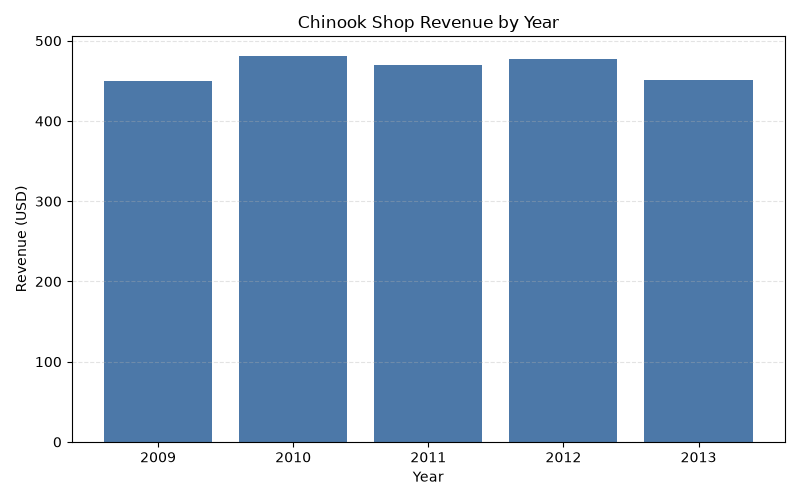

In [21]:
def run_in_container(code):
    """Run Python code in a new sandbox container; return what it printed."""
    (OUTPUTS / "run.py").write_text(code)
    result = subprocess.run(
        ["docker", "run", *SANDBOX_FLAGS, *MOUNT, "chinook-sandbox", "timeout", "20", "python", "run.py"],
        capture_output=True, text=True,
    )
    printed = result.stdout + result.stderr
    return printed or f"finished with exit code {result.returncode}, printed nothing"


if DOCKER_OK:
    local_code = chart_code.replace("plt.show()", "plt.savefig('container_chart.png')")
    print(run_in_container(local_code))
    display(Image(filename=OUTPUTS / "container_chart.png", width=600))
else:
    print(SKIP)

`finished with exit code 0, printed nothing`: exit code 0 means the code finished without an error, and it has no `print`, only the `savefig`. The same code drew the same chart, this time on our machine, in a container where the probe found
no `.env` and no network.

**Checkpoint E (optional).** Docker's version, or the skip line; the image with Python 3.13.18, matplotlib 3.11.2 and
the user `sandbox`; the probe in the container: `.env there: False`, `key in environment: False`,
`network: blocked, gaierror`; inside the container with every limit, the user `sandbox` and `Read-only file system` for `/etc`; the chart
saved as `outputs/container_chart.png`.

---

## What you can do now

- Give one agent a function tool that runs in your Python and the hosted code interpreter, write the loop that runs
  only the function calls, and read a run item by item (Part B).
- Read the code behind a chart and count the numbers the model typed into it (Part C).
- Hand a query's rows to the code interpreter as an uploaded file, so the model writes the steps and never the data,
  and delete the files afterwards (Part D).
- With Docker, run model-written code in a container with no network, a read-only root, limits, a user who is not
  root and one mounted folder, and say what the code can reach inside it (Part E).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `No chart came back: the code saved it in the container without showing it.` | the model saved the chart to a file and did not call `plt.show()`, so no image came back | keep "Show every chart with plt.show()" in `SYSTEM`, and ask again |
| `docker server: failed to connect to the docker API at ...` | Docker is installed but not running | start Docker Desktop (on Linux, `sudo systemctl start docker`) and run Part E from its first cell; or skip Part E |
| `ModuleNotFoundError: No module named 'pandas'` from `run_in_container` | the image has only matplotlib and numpy installed, and the code imports another library | add the library to the Dockerfile's `pip install` line and run the build cell again |
| `FileNotFoundError` for `container_chart.png`, or an error printed above the chart | the code did not reach `plt.savefig` in the container | read what `run_in_container` printed; delete `outputs/container_chart.png` before you run again, so the cell cannot show an old chart as if it were the new one |
| `finished with exit code 124, printed nothing` | the code ran longer than 20 seconds, and `timeout` stopped it | expected for an endless loop; for slow real work, raise the `timeout 20` |
| `finished with exit code 137, printed nothing` | the code used more than the 256 MB memory limit, and the kernel stopped it | for real work, raise `--memory` and `--memory-swap` together |

## Challenge

1. **A second chart, with the rows handed to the code.** With Part D's `run_sql` in place, ask the agent: *Make a bar
   chart of the five countries with the most revenue.* Print all the code it wrote, and check it for typed numbers
   against the database's own top five (`BillingCountry` and `ROUND(SUM(Total), 2)` from `invoices`). Delete the
   uploaded files afterwards. *Expected:* the code reads the CSV file, none of the five country totals is typed in
   (`0 of 5`), and the highest bar is the USA at $523.06.
2. **Test the container's limits** (needs Docker). Send two programs of your own through `run_in_container`:
   `while True: pass`, and one that builds a 300 MB bytes object (`b"x" * (300 * 1024 * 1024)`). *Expected:*
   `finished with exit code 124, printed nothing` for the first (the `timeout` program stopped it after 20 seconds)
   and exit code 137 for the second (128 + 9: the kernel stopped it with signal 9 at the 256 MB limit). Say which
   flag or command stopped each.

A worked solution, run with its outputs, is in `solved/17b_code_execution_at_the_desk_solution.ipynb`.

## Going further

**The Dockerfile, line by line.** The image Part E built:

In [22]:
print((ROOT / "17_Code_Execution" / "resources" / "Dockerfile").read_text())

# The sandbox image for lab 17's container runner.
# Build it from the repository folder:  docker build -t chinook-sandbox 17_Code_Execution/resources
FROM python:3.13.18-slim

# The one library the chart code needs, pinned to the version the repository uses
RUN pip install --no-cache-dir matplotlib==3.11.2

# An ordinary user with no special rights; code in the container runs as this user, never as root
RUN useradd --create-home --uid 1000 sandbox
USER sandbox

# Matplotlib keeps a small cache; /tmp is the only writable place besides the mounted folder
ENV MPLCONFIGDIR=/tmp/matplotlib
WORKDIR /work



- **`FROM python:3.13.18-slim`** starts from the official Python image: a small Debian Linux with Python 3.13.18. The
  exact patch release means every build gets the same Python.
- **`RUN pip install --no-cache-dir matplotlib==3.11.2`** adds the one library chart code needs, at the version this
  repository pins (numpy comes with it). Nothing else: no database driver, no `requests`.
- **`RUN useradd --create-home --uid 1000 sandbox`** and **`USER sandbox`** create an ordinary user and make every
  command run as it. Code in the container is not root, so it cannot change the image's system files.
- **`ENV MPLCONFIGDIR=/tmp/matplotlib`** tells matplotlib where to keep the small cache it writes when it starts:
  `/tmp` is the only writable place besides the mounted folder.
- **`WORKDIR /work`** is the folder code starts in, where `outputs/` is mounted.

**The flags, and what each one stops.**

| Flag | What it stops |
|---|---|
| `--network none` | sending data out, or downloading anything |
| `--volume OUTPUTS:/work` (and nothing else mounted) | seeing your files: the container's disk is the image, plus this one folder |
| `--read-only`, with `--tmpfs /tmp` | changing the image's files; only `/tmp` (in memory) and `/work` can be written |
| `--memory 256m --memory-swap 256m` | using all your memory; the kernel stops the code at 256 MB (exit code 137) |
| `--cpus 1` | taking every CPU core |
| `--pids-limit 64` | starting processes without end |
| `--cap-drop ALL`, `--security-opt no-new-privileges` | using root's capabilities (its special rights), or gaining more rights while it runs |
| `--rm` | leaving stopped containers behind |
| `timeout 20` (inside the container) | running forever (exit code 124) |

A container shares your machine's operating system kernel, so a flaw in the kernel can let code escape the container and reach your machine. For code from
many users, or code you have a reason to distrust, teams go one step further: a micro-VM (Firecracker, Kata
Containers) boots its own small kernel, and gVisor puts a kernel written in user space between the code and yours.

**What a chart costs.** Each run made a few model calls and started one container session. The cell below adds up
the two runs of Parts B and D: tokens at the prices in `models.env`, plus one session per container.

In [23]:
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"]) / 1_000_000
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"]) / 1_000_000
SESSION = float(settings["PRICE_CONTAINER_SESSION_USD"])

for name, run in [("Part B", run_typed), ("Part D", run_file)]:
    tokens_usd = sum(r.usage.input_tokens * PRICE_IN + r.usage.output_tokens * PRICE_OUT for r in run)
    sessions = len({call.container_id for call in code_calls(run)})
    print(f"{name}: {len(run)} model calls, tokens ${tokens_usd:.5f} + {sessions} session(s) = ${tokens_usd + sessions * SESSION:.4f}")

Part B: 2 model calls, tokens $0.00046 + 1 session(s) = $0.0305
Part D: 2 model calls, tokens $0.00046 + 1 session(s) = $0.0305


In our run each chart took 2 model calls, $0.00046 in tokens, and one container session: at most $0.0305 a chart. The session is most of the bill. OpenAI's pricing page lists the 1 GB
container at $0.03 per 20-minute session, and says eligible sessions are "billed by the minute, with a 5-minute
minimum per session". Our sum counts every session at the full $0.03, so it is the most these runs can cost; a
session billed by the minute costs less.

**Running your own code on the hosted interpreter.** There is no request that runs a given piece of code: the model
always writes the code that runs. To run code of ours there, we ask the model to run it exactly as written.
The model can still change a line while it copies the code: a probe with the line `from pathlib import Path` has
come back as `from pathlib import import Path`, a line that is not Python. So compare `code_interpreter_call.code`
with what you sent, and treat a difference as a failed run. For code of your own, a container you control (Part E) is the better runner.

**The same choice in a framework.** The OpenAI Agents SDK's sandbox agents give an agent a workspace with shell and
file tools, and let you pick where it runs: a local client, Docker, or a hosted provider (E2B, Modal, Daytona and
others). Its documentation says that on Linux the local client adds no confinement to commands (on macOS it limits files
but not the network), and points untrusted commands to Docker or a hosted sandbox, for the reason Part E gives: a plain process on
your machine runs as you, with your files and your network.

## Resources

- [OpenAI: code interpreter](https://developers.openai.com/api/docs/guides/tools-code-interpreter): containers, their
  reuse and expiry, files in the container, and images a chart returns
- [OpenAI: create a file](https://developers.openai.com/api/reference/resources/files/methods/create): `files.create`
  and its `purpose`
- [OpenAI: pricing, built-in tools](https://developers.openai.com/api/docs/pricing): the container session prices
- [Python: `csv`](https://docs.python.org/3/library/csv.html): `csv.writer`, `writerow`, `writerows`
- [Docker: `docker container run`](https://docs.docker.com/reference/cli/docker/container/run/): every flag in
  Part E
- [Docker: resource constraints](https://docs.docker.com/engine/containers/resource_constraints/): `--memory`,
  `--memory-swap`, `--cpus`
- [Dockerfile reference](https://docs.docker.com/reference/dockerfile/): `FROM`, `RUN`, `USER`, `ENV`, `WORKDIR`
- [OpenAI Agents SDK: sandbox agents](https://openai.github.io/openai-agents-python/sandbox_agents/) and
  [sandbox clients](https://openai.github.io/openai-agents-python/sandbox/clients/): where a sandbox agent's commands
  run
- [gVisor](https://gvisor.dev/docs/) and [Firecracker](https://firecracker-microvm.github.io/): two ways to isolate code more
  strongly than a container, without a full virtual machine

Back to [notebook 1](17a_meet_code_execution.ipynb). Next:
[Lab 18: How to choose an agent design](../18_Agent_Designs/README.md).